# Pengolahan Data Uji Penetrasi Konus / Sondir (Cone Penetration Test - CPT)
### Mengacu pada SNI 2827:2008: *Cara Uji Penetrasi Lapangan dengan Alat Sondir*

---

**Informasi Penyelidikan Lapangan:**
* **Proyek:** Pemb. Pabrik - PT. Bimaska Sukses Jaya
* **Lokasi:** Sukamantri, Pasar Kemis, Tangerang - Banten
* **Titik Sondir:** S-1
* **Tanggal:** 25-Apr-20
* **Operator:** Ariyanto
* **Checked By:** Eko Prasetyo A.
* **Kapasitas Alat Sondir:** 5.0 ton
* **Muka Air Tanah (GWL):** 6.0 meter

Notebook ini menyajikan panduan praktis dan komprehensif pengolahan data uji penetrasi konus statis di lapangan (sondir mekanis/Dutch Cone Penetrometer dengan konus ganda Begemann), mulai dari impor data mentah CSV, perhitungan parameter geoteknik berbasis standar SNI 2827:2008, *Exploratory Data Analysis* (EDA), hingga visualisasi profil sondir standar industri geoteknik.

## 1. Landasan Teori & Formulasi SNI 2827:2008

Pengujian sondir statis bertujuan mengetahui perlawanan penetrasi konus ($q_c$) dan hambatan pelekat ($f_s$) dari lapisan tanah secara kontinu setiap interval kedalaman 20 cm ($0.20\text{ m}$).

Alat yang digunakan adalah **Konus Ganda (Begemann Friction Cone)** dengan parameter standar:
* Sudut konus: $60^\circ$
* Luas proyeksi penampang konus ($A_c$): $10\text{ cm}^2$ (diameter konus $35.7\text{ mm}$)
* Luas selimut geser konus ($A_s$): $120\text{ cm}^2$ (atau $150\text{ cm}^2$)

### Rumus Perhitungan Berdasarkan SNI 2827:2008:
1. **Perlawanan Penetrasi Konus ($q_c$):**
   $$q_c = R_1 \quad (\text{kg/cm}^2)$$
   Di mana $R_1$ adalah pembacaan manometer pertama saat ujung konus ditekan ke bawah sedalam 4 cm.

2. **Hambatan Lekat / Frictional Resistance ($HL$):**
   $$HL = R_2 - R_1 \quad (\text{kg/cm}^2)$$
   Di mana $R_2$ adalah pembacaan manometer kedua saat stang luar mendorong konus dan selimut geser bersamaan sedalam 4 cm berikutnya.

3. **Geseran Lokal / Local Friction ($f_s$):**
   $$f_s = \frac{R_2 - R_1}{12} \quad (\text{kg/cm}^2)$$
   *(Faktor 12 diperoleh dari perbandingan luas bidang geser konus $A_s = 120\text{ cm}^2$ terhadap luas penampang piston/konus $A_c = 10\text{ cm}^2$)*

4. **Jumlah Hambatan Pelekat / Total Friction ($T_f$ atau $JHP$):**
   $$T_f = \sum (f_s \times \Delta z) = \sum \left( f_s \times 20\text{ cm} \right) \quad (\text{kg/cm})$$

5. **Rasio Gesekan / Friction Ratio ($FR$):**
   $$FR = \frac{f_s}{q_c} \times 100\% = \frac{f_s}{R_1} \times 100\%$$

## 2. Import Library Python

Kita menggunakan pustaka standar data science dan visualisasi geoteknik:
* `pandas` untuk manipulasi dan analisis data tabular.
* `numpy` untuk komputasi numerik vektor.
* `matplotlib.pyplot` dan `matplotlib.ticker` untuk plotting profil sondir presisi tinggi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as patches
import matplotlib.lines as lines
import warnings

warnings.filterwarnings('ignore')

# Konfigurasi tampilan Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Library berhasil diimpor!")

Library berhasil diimpor!


## 3. Menyiapkan dan Mengimpor Data Input CSV

Data lapangan dicatat dalam file CSV `data/data_sondir_raw.csv` dengan kolom:
* `Depth_m`: Kedalaman pengujian (meter)
* `R1_kg_cm2`: Pembacaan manometer 1 (Perlawanan Konus $q_c$)
* `R2_kg_cm2`: Pembacaan manometer 2 (Perlawanan Konus + Geser Selimut)

In [2]:
# Membaca data mentah dari file CSV
df_raw = pd.read_csv('data/data_sondir_raw.csv')

print(f"Total baris data: {len(df_raw)}")
print("\n--- Cuplikan 10 Data Pertama (Raw Field Data) ---")
df_raw.head(10)

Total baris data: 44

--- Cuplikan 10 Data Pertama (Raw Field Data) ---


,Depth_m,R1_kg_cm2,R2_kg_cm2
0,0.0,0,0
1,0.2,5,10
2,0.4,10,15
3,0.6,10,20
4,0.8,15,25
5,1.0,20,35
6,1.2,25,40
7,1.4,25,45
8,1.6,30,65
9,1.8,35,70


In [3]:
# Pengecekan tipe data dan kelengkapan (Data Hygiene)
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Depth_m    44 non-null     float64
 1   R1_kg_cm2  44 non-null     int64  
 2   R2_kg_cm2  44 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 1.2 KB


## 4. Perhitungan Parameter Geoteknik Sesuai SNI 2827:2008

Kita menerapkan rumus SNI secara tervektorisasi:
1. $q_c = R_1$
2. Hambatan Lekat = $R_2 - R_1$
3. Geseran Lokal ($f_s$) = $(R_2 - R_1) / 12$
4. Jumlah Hambatan Pelekat ($T_f$) = kumulatif dari $(f_s \times 20)$
5. Rasio Gesekan ($FR$) = $(f_s / q_c) \times 100\%$

In [4]:
df = df_raw.copy()

# 1. Perlawanan Konus (qc)
df['qc_kg_cm2'] = df['R1_kg_cm2']

# 2. Hambatan Lekat (Frictional Resistance)
df['Frictional_Resistance'] = df['R2_kg_cm2'] - df['R1_kg_cm2']

# 3. Geseran Lokal (Local Friction - fs)
df['Local_Friction_fs'] = np.round(df['Frictional_Resistance'] / 12.0, 2)

# 4. Total Friction (Tf) - akumulasi fs * delta_z (20 cm)
df['Total_Friction_Tf'] = np.round((df['Local_Friction_fs'] * 20.0).cumsum(), 1)

# 5. Friction Ratio (FR)
df['Friction_Ratio_FR'] = np.where(
    df['qc_kg_cm2'] > 0,
    np.round((df['Local_Friction_fs'] / df['qc_kg_cm2']) * 100.0, 2),
    0.0
)

print("--- Data Hasil Olahan Sesuai SNI 2827:2008 (10 Baris Pertama) ---")
df[['Depth_m', 'qc_kg_cm2', 'R2_kg_cm2', 'Frictional_Resistance', 'Local_Friction_fs', 'Total_Friction_Tf', 'Friction_Ratio_FR']].head(10)

--- Data Hasil Olahan Sesuai SNI 2827:2008 (10 Baris Pertama) ---


,Depth_m,qc_kg_cm2,R2_kg_cm2,Frictional_Resistance,Local_Friction_fs,Total_Friction_Tf,Friction_Ratio_FR
0,0.0,0,0,0,0.00,0.0,0.00
1,0.2,5,10,5,0.42,8.4,8.40
2,0.4,10,15,5,0.42,16.8,4.20
3,0.6,10,20,10,0.83,33.4,8.30
4,0.8,15,25,10,0.83,50.0,5.53
5,1.0,20,35,15,1.25,75.0,6.25
6,1.2,25,40,15,1.25,100.0,5.00
7,1.4,25,45,20,1.67,133.4,6.68
8,1.6,30,65,35,2.92,191.8,9.73
9,1.8,35,70,35,2.92,250.2,8.34


## 5. Exploratory Data Analysis (EDA)

EDA dilakukan untuk menganalisis karakteristik geoteknik lapisan tanah:
1. Statistik ringkasan nilai $q_c, f_s, T_f, FR$
2. Klasifikasi konsistensi tanah berdasarkan $q_c$
3. Klasifikasi estimasi tipe tanah berdasarkan Friction Ratio ($FR$)
4. Identifikasi kedalaman lapisan tanah keras ($q_c \ge 150 - 250\text{ kg/cm}^2$)

In [5]:
# 5.1 Statistik Deskriptif
summary_stats = df[['qc_kg_cm2', 'Local_Friction_fs', 'Total_Friction_Tf', 'Friction_Ratio_FR']].describe().round(2)
print("=== STATISTIK DESKRIPTIF DATA SONDIR S-1 ===")
summary_stats

=== STATISTIK DESKRIPTIF DATA SONDIR S-1 ===


,qc_kg_cm2,Local_Friction_fs,Total_Friction_Tf,Friction_Ratio_FR
count,44.00,44.00,44.00,44.00
mean,75.34,3.65,938.87,5.21
std,75.53,3.69,814.09,2.04
min,0.00,0.00,0.00,0.00
25%,28.75,1.25,360.60,3.83
50%,45.00,2.08,763.00,5.00
75%,106.25,3.86,1227.75,6.31
max,350.00,14.17,3209.00,9.73


In [6]:
# 5.2 Klasifikasi Konsistensi dan Jenis Lapisan Tanah
def klasifikasi_konsistensi(qc):
    if qc == 0:
        return 'Permukaan (0 kg/cm²)'
    elif qc < 5:
        return 'Sangat Lunak (Very Soft)'
    elif qc < 10:
        return 'Lunak (Soft)'
    elif qc < 20:
        return 'Sedang (Medium)'
    elif qc < 40:
        return 'Kaku (Stiff)'
    elif qc < 80:
        return 'Sangat Kaku (Very Stiff)'
    else:
        return 'Keras (Hard)'

def klasifikasi_jenis_tanah(fr):
    if fr == 0:
        return 'Permukaan'
    elif fr < 1.0:
        return 'Pasir / Pasir Kasar (Sand)'
    elif fr < 3.0:
        return 'Lanau Berpasir (Silty Sand)'
    elif fr <= 5.0:
        return 'Lanau / Lempung Kelanauan (Clayey Silt)'
    else:
        return 'Lempung Plastis Tinggi (Highly Plastic Clay)'

df['Konsistensi'] = df['qc_kg_cm2'].apply(klasifikasi_konsistensi)
df['Estimasi_Jenis_Tanah'] = df['Friction_Ratio_FR'].apply(klasifikasi_jenis_tanah)

print("=== DISTRIBUSI KONSISTENSI TANAH BERDASARKAN qc ===")
print(df['Konsistensi'].value_counts())
print("\n=== DISTRIBUSI ESTIMASI JENIS TANAH BERDASARKAN FR ===")
print(df['Estimasi_Jenis_Tanah'].value_counts())

=== DISTRIBUSI KONSISTENSI TANAH BERDASARKAN qc ===
Konsistensi
Kaku (Stiff)                13
Keras (Hard)                13
Sangat Kaku (Very Stiff)    12
Sedang (Medium)              4
Permukaan (0 kg/cm²)         1
Lunak (Soft)                 1
Name: count, dtype: int64

=== DISTRIBUSI ESTIMASI JENIS TANAH BERDASARKAN FR ===
Estimasi_Jenis_Tanah
Lempung Plastis Tinggi (Highly Plastic Clay)    21
Lanau / Lempung Kelanauan (Clayey Silt)         18
Lanau Berpasir (Silty Sand)                      4
Permukaan                                        1
Name: count, dtype: int64


In [7]:
# 5.3 Stratigrafi Lapisan Berdasarkan Kedalaman
strat_df = df[['Depth_m', 'qc_kg_cm2', 'Friction_Ratio_FR', 'Konsistensi', 'Estimasi_Jenis_Tanah']]
print("=== STRATIGRAFI RINGKAS TIAP RENTANG KEDALAMAN ===")
strat_df.iloc[[0, 5, 10, 15, 20, 25, 30, 35, 40, 43]]

=== STRATIGRAFI RINGKAS TIAP RENTANG KEDALAMAN ===


,Depth_m,qc_kg_cm2,Friction_Ratio_FR,Konsistensi,Estimasi_Jenis_Tanah
0,0.0,0,0.00,Permukaan (0 kg/cm²),Permukaan
5,1.0,20,6.25,Kaku (Stiff),Lempung Plastis Tinggi (Highly Plastic Clay)
10,2.0,35,9.51,Kaku (Stiff),Lempung Plastis Tinggi (Highly Plastic Clay)
15,3.0,30,4.17,Kaku (Stiff),Lanau / Lempung Kelanauan (Clayey Silt)
20,4.0,30,5.57,Kaku (Stiff),Lempung Plastis Tinggi (Highly Plastic Clay)
25,5.0,50,3.34,Sangat Kaku (Very Stiff),Lanau / Lempung Kelanauan (Clayey Silt)
30,6.0,70,3.57,Sangat Kaku (Very Stiff),Lanau / Lempung Kelanauan (Clayey Silt)
35,7.0,140,4.16,Keras (Hard),Lanau / Lempung Kelanauan (Clayey Silt)
40,8.0,200,6.25,Keras (Hard),Lempung Plastis Tinggi (Highly Plastic Clay)
43,8.6,350,3.57,Keras (Hard),Lanau / Lempung Kelanauan (Clayey Silt)


## 6. Pembuatan Grafik Profil Sondir Standar Industri (SNI 2827:2008)

Grafik profil sondir standar menyajikan dua panel kurva berdampingan:
1. **Panel Kiri:** Kurva Perlawanan Konus $q_c$ (garis biru solid) dan Jumlah Hambatan Pelekat $T_f/10$ (garis putus-putus hijau) terhadap kedalaman.
2. **Panel Kanan:** Kurva Rasio Gesekan $FR$ (garis hitam solid) terhadap kedalaman.
3. **Karakteristik Visual Geoteknik:**
   * Sumbu vertikal (kedalaman) **dibalik** (`inverted`, 0 meter di puncak hingga 10 meter di dasar).
   * Grid ganda (grid mayor dan grid minor biru muda) untuk kemudahan pembacaan koordinat titik lapangan.
   * Header resmi mencakup Nomor Titik Uji, Proyek, Lokasi, Tanggal, Operator, Kapasitas, dan Muka Air Tanah (GWL).

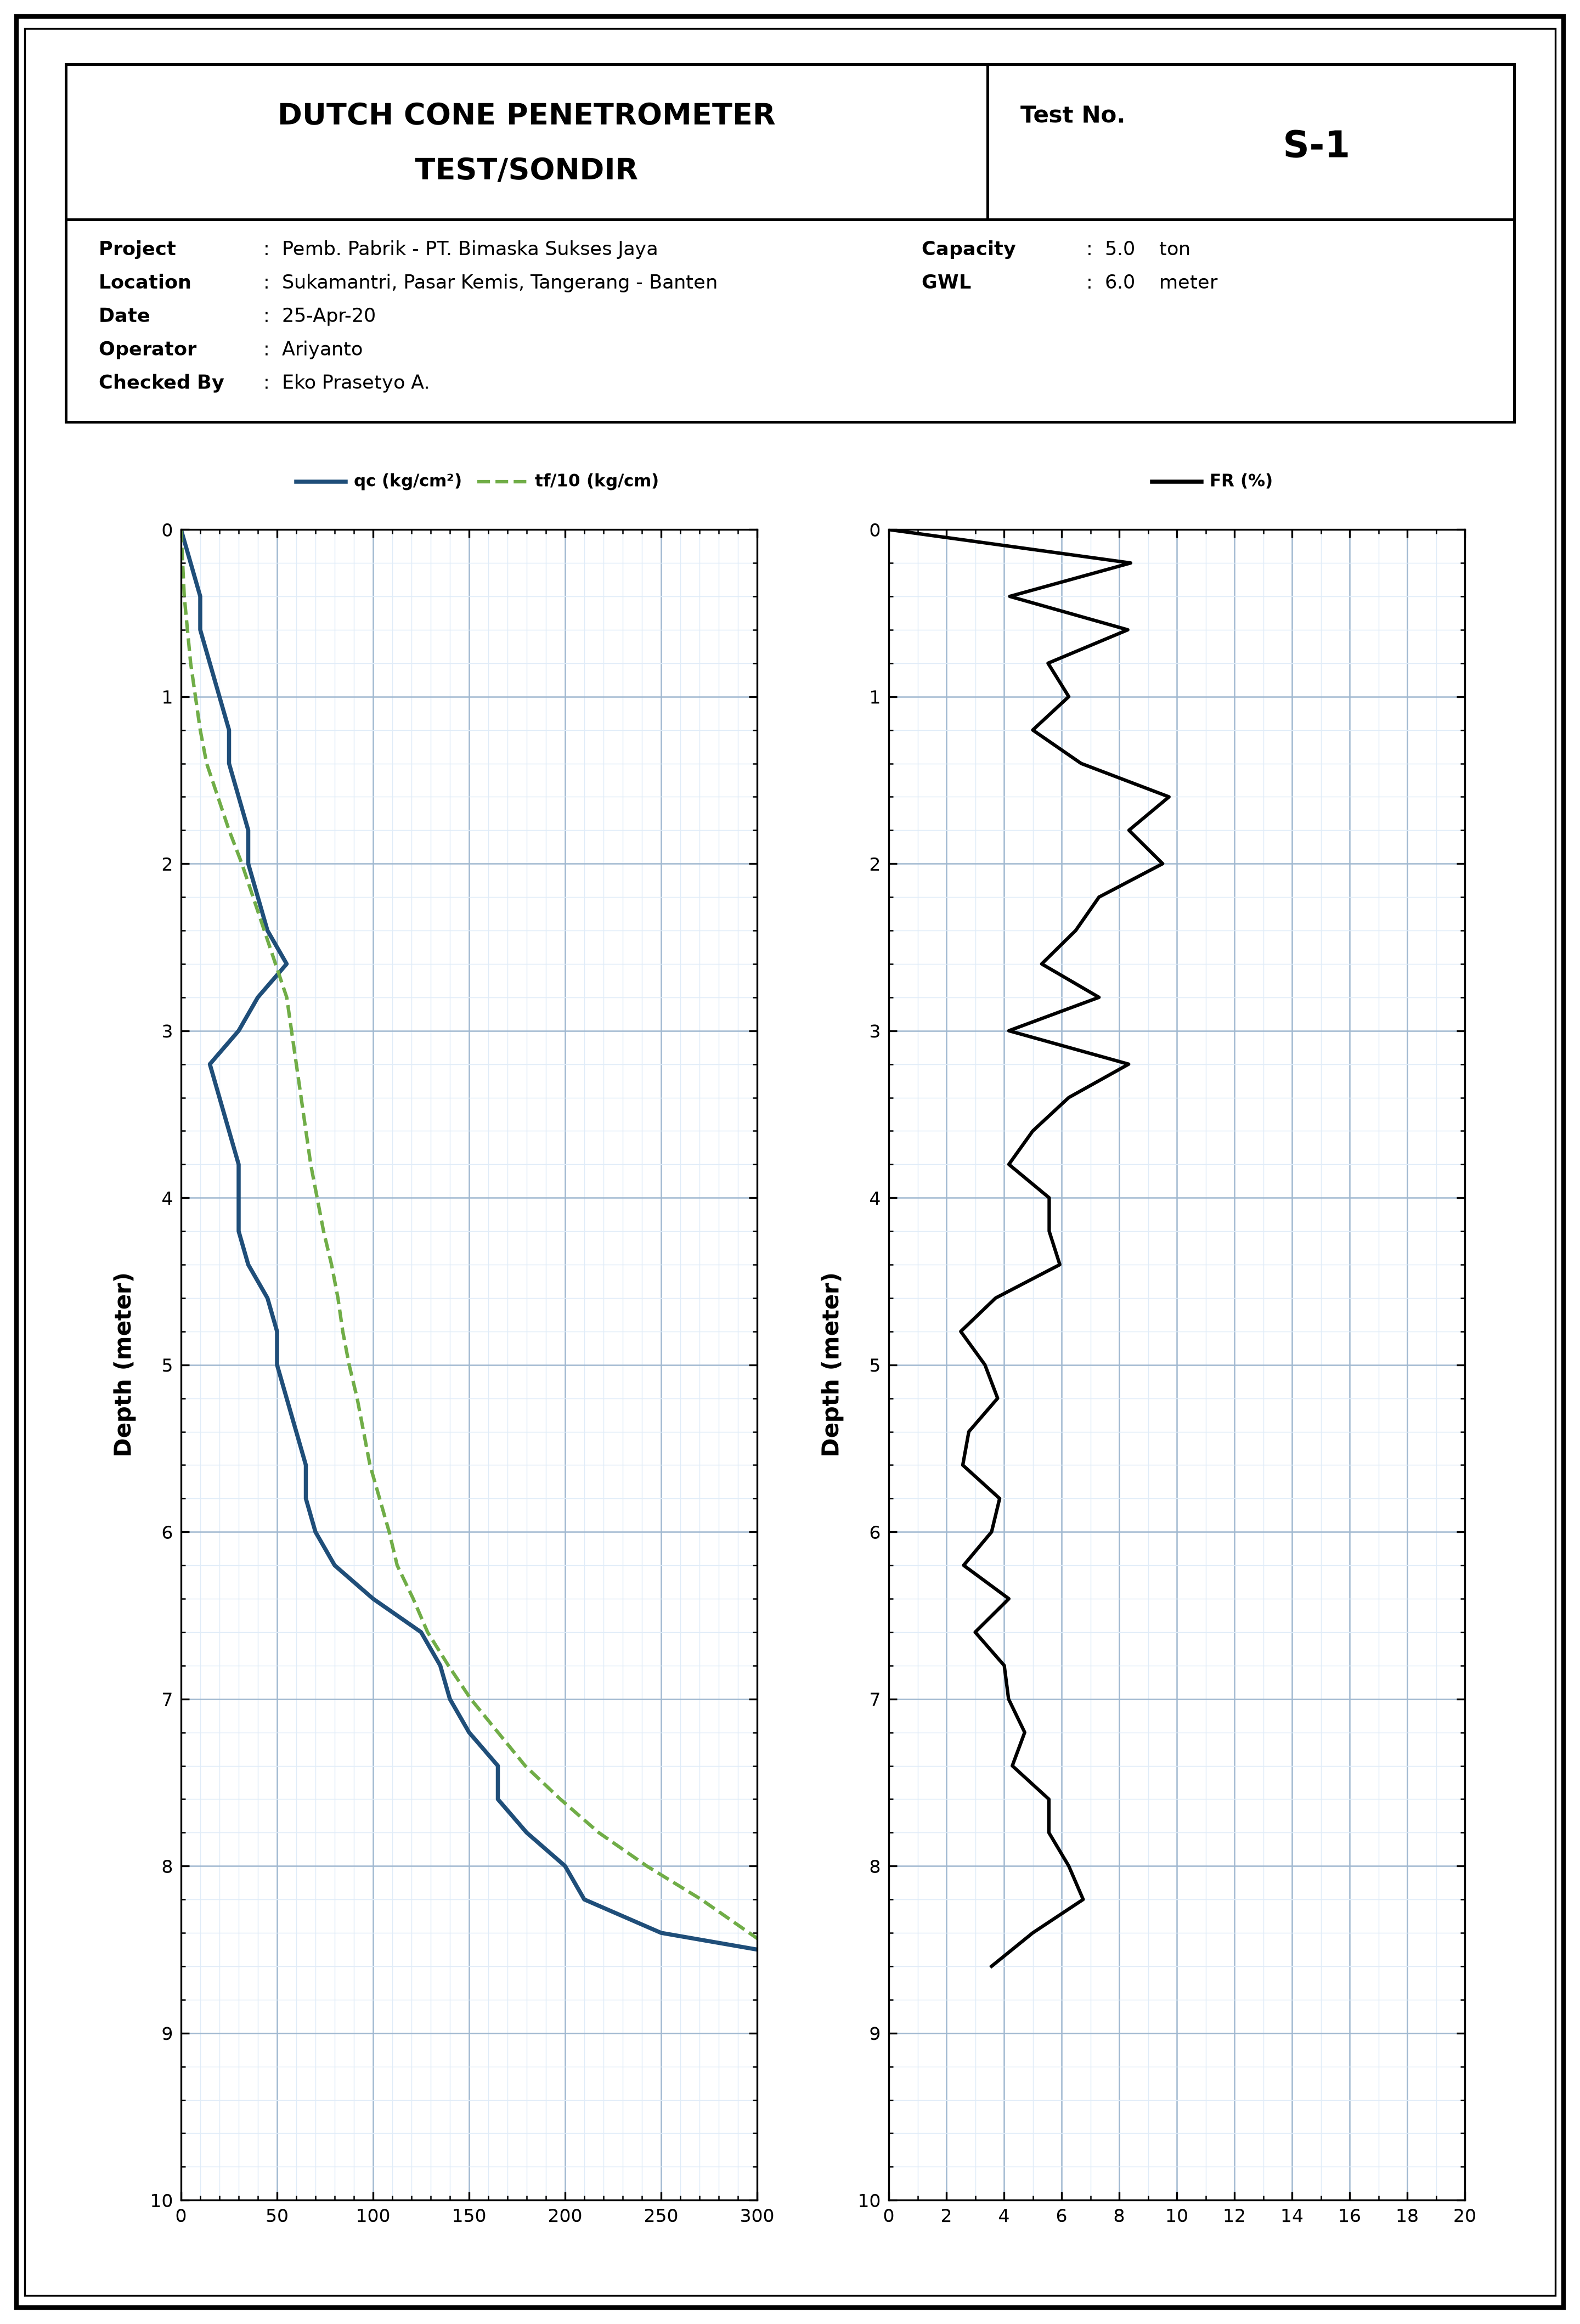

Grafik profil sondir berhasil dibuat dan disimpan sebagai 'output/grafik_sondir_s1.png'!


In [8]:
# Setup Gambar Matplotlib
fig = plt.figure(figsize=(10, 14.5), dpi=300, facecolor='white')

# 1. Garis Bingkai Luar Ganda (Double Border)
fig.add_artist(patches.Rectangle((0.03, 0.02), 0.94, 0.96, linewidth=2.0, edgecolor='black', facecolor='none'))
fig.add_artist(patches.Rectangle((0.035, 0.025), 0.93, 0.95, linewidth=0.8, edgecolor='black', facecolor='none'))

# 2. Header Area Penyelidikan Lapangan
fig.add_artist(patches.Rectangle((0.06, 0.81), 0.88, 0.15, linewidth=1.2, edgecolor='black', facecolor='none'))
fig.add_artist(lines.Line2D([0.06, 0.94], [0.895, 0.895], linewidth=1.2, color='black'))
fig.add_artist(lines.Line2D([0.62, 0.62], [0.895, 0.96], linewidth=1.2, color='black'))

# Judul Utama Header
fig.text(0.34, 0.938, 'DUTCH CONE PENETROMETER', fontsize=13, fontweight='bold', ha='center', va='center')
fig.text(0.34, 0.915, 'TEST/SONDIR', fontsize=13, fontweight='bold', ha='center', va='center')

# Nomor Titik Uji
fig.text(0.64, 0.938, 'Test No.', fontsize=10, fontweight='bold', va='center')
fig.text(0.82, 0.925, 'S-1', fontsize=16, fontweight='bold', ha='center', va='center')

# Metadata Proyek
labels_col1 = ['Project', 'Location', 'Date', 'Operator', 'Checked By']
vals_col1 = [
    ':  Pemb. Pabrik - PT. Bimaska Sukses Jaya',
    ':  Sukamantri, Pasar Kemis, Tangerang - Banten',
    ':  25-Apr-20',
    ':  Ariyanto',
    ':  Eko Prasetyo A.'
]
y_start = 0.880
y_step = 0.014

for i in range(len(labels_col1)):
    fig.text(0.08, y_start - i*y_step, labels_col1[i], fontsize=8.5, fontweight='bold', family='sans-serif')
    fig.text(0.18, y_start - i*y_step, vals_col1[i], fontsize=8.5, family='sans-serif')

labels_col2 = ['Capacity', 'GWL']
vals_col2 = [':  5.0    ton', ':  6.0    meter']
for i in range(len(labels_col2)):
    fig.text(0.58, y_start - i*y_step, labels_col2[i], fontsize=8.5, fontweight='bold', family='sans-serif')
    fig.text(0.68, y_start - i*y_step, vals_col2[i], fontsize=8.5, family='sans-serif')

# 3. Legenda di Atas Masing-Masing Grafik
fig.add_artist(lines.Line2D([0.20, 0.23], [0.785, 0.785], linewidth=1.8, color='#1f4e79'))
fig.text(0.235, 0.785, 'qc (kg/cm²)', fontsize=7.5, fontweight='bold', va='center')

fig.add_artist(lines.Line2D([0.31, 0.34], [0.785, 0.785], linewidth=1.5, color='#70ad47', linestyle='--'))
fig.text(0.345, 0.785, 'tf/10 (kg/cm)', fontsize=7.5, fontweight='bold', va='center')

fig.add_artist(lines.Line2D([0.72, 0.75], [0.785, 0.785], linewidth=1.8, color='black'))
fig.text(0.755, 0.785, 'FR (%)', fontsize=7.5, fontweight='bold', va='center')

# 4. Sumbu Grafik (Axes)
ax1 = fig.add_axes([0.13, 0.065, 0.35, 0.70])
ax2 = fig.add_axes([0.56, 0.065, 0.35, 0.70])

# --- Plot Sisi Kiri (qc dan tf/10) ---
ax1.plot(df['qc_kg_cm2'], df['Depth_m'], color='#1f4e79', lw=1.8)
ax1.plot(df['Total_Friction_Tf']/10.0, df['Depth_m'], color='#70ad47', lw=1.5, linestyle='--')
ax1.set_xlim(0, 300)
ax1.set_ylim(10, 0) # Kedalaman dibalik (0 di atas)
ax1.set_ylabel('Depth (meter)', fontsize=10, fontweight='bold', labelpad=6)
ax1.xaxis.set_major_locator(ticker.MultipleLocator(50))
ax1.xaxis.set_minor_locator(ticker.MultipleLocator(10))
ax1.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax1.yaxis.set_minor_locator(ticker.MultipleLocator(0.2))
ax1.grid(True, which='major', color='#a0b8d0', linestyle='-', linewidth=0.6)
ax1.grid(True, which='minor', color='#e0ecf8', linestyle='-', linewidth=0.35)
ax1.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=8)

# --- Plot Sisi Kanan (FR %) ---
ax2.plot(df['Friction_Ratio_FR'], df['Depth_m'], color='black', lw=1.5)
ax2.set_xlim(0, 20)
ax2.set_ylim(10, 0) # Kedalaman dibalik
ax2.set_ylabel('Depth (meter)', fontsize=10, fontweight='bold', labelpad=6)
ax2.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax2.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax2.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax2.yaxis.set_minor_locator(ticker.MultipleLocator(0.2))
ax2.grid(True, which='major', color='#a0b8d0', linestyle='-', linewidth=0.6)
ax2.grid(True, which='minor', color='#e0ecf8', linestyle='-', linewidth=0.35)
ax2.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=8)

# Simpan dan Tampilkan
plt.savefig('output/grafik_sondir_s1.png', dpi=300, facecolor='white')
plt.show()
print("Grafik profil sondir berhasil dibuat dan disimpan sebagai 'output/grafik_sondir_s1.png'!")

## 7. Kesimpulan & Rekomendasi Geoteknik

Berdasarkan hasil analisis data dan grafik profil sondir titik **S-1**:

1. **Kondisi Tanah Dangkal ($0.00 - 2.80\text{ m}$):**
   * Nilai $q_c$ berkisar antara $5 - 40\text{ kg/cm}^2$ dengan $FR$ rata-rata $> 5\%$.
   * Menunjukkan formasi lempung plastis lunak hingga kaku sedang (*soft to medium stiff clay*). Pondasi telapak dangkal (*shallow footings*) untuk struktur beban berat berisiko mengalami penurunan konsolidasi berlebih.

2. **Lapisan Transisi ($2.80 - 6.20\text{ m}$):**
   * Terjadi peningkatan resistensi konus secara bertahap dari $q_c = 15\text{ kg/cm}^2$ hingga $q_c = 80\text{ kg/cm}^2$.
   * Nilai $FR$ menurun ke rentang $2.5\% - 4.2\%$, mengindikasikan material lempung kelanauan hingga lanau berpasir (*silty clay to sandy silt*).
   * Muka air tanah (GWL) tercatat pada kedalaman $6.00\text{ meter}$.

3. **Lapisan Tanah Keras / Daya Dukung Tinggi ($6.40 - 8.60\text{ m}$):**
   * Terjadi lonjakan tajam nilai $q_c$ dari $100\text{ kg/cm}^2$ (kedalaman 6.4 m), $200\text{ kg/cm}^2$ (kedalaman 8.0 m), hingga mencapai **$q_c = 350\text{ kg/cm}^2$** dan perlawanan total $R_2 = 500\text{ kg/cm}^2$ pada kedalaman **$8.60\text{ meter}$**.
   * Penetrasi dihentikan sesuai kriteria **SNI 2827:2008 Pasal 6.3** karena telah mencapai kapasitas maksimum alat sondir (5.0 ton / $R_2 = 500\text{ kg/cm}^2$).

4. **Rekomendasi Pondasi:**
   * Untuk bangunan pabrik berbeban berat (PT. Bimaska Sukses Jaya), direkomendasikan menggunakan sistem **pondasi dalam (Tiang Pancang / Mini Pile / Spun Pile)** dengan kedalaman ujung tiang (*end bearing*) dipancang hingga menyentuh lapisan tanah keras pada kedalaman **$8.00 - 8.60\text{ meter}$**.
   * Total hambatan pelekat yang besar ($T_f = 3208.3\text{ kg/cm}$) memberikan kontribusi daya dukung friksi selimut tiang (*skin friction*) yang sangat signifikan bagi kapasitas ultimit pondasi tiang.